In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [5]:
import os
print(os.listdir(r"C:\Users\mestr\Downloads\uber"))

['uber.csv']


In [6]:
df = pd.read_csv(r"C:\Users\mestr\Downloads\uber\uber.csv")
print(df.head())
print(df.shape)

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [7]:
df = df.dropna().drop_duplicates()

q1 = df['fare_amount'].quantile(0.25)
q3 = df['fare_amount'].quantile(0.75)
iqr = q3 - q1

df = df[(df['fare_amount'] >= q1-1.5*iqr) &
        (df['fare_amount'] <= q3+1.5*iqr)]

print(df.shape)

(182833, 9)


<Axes: >

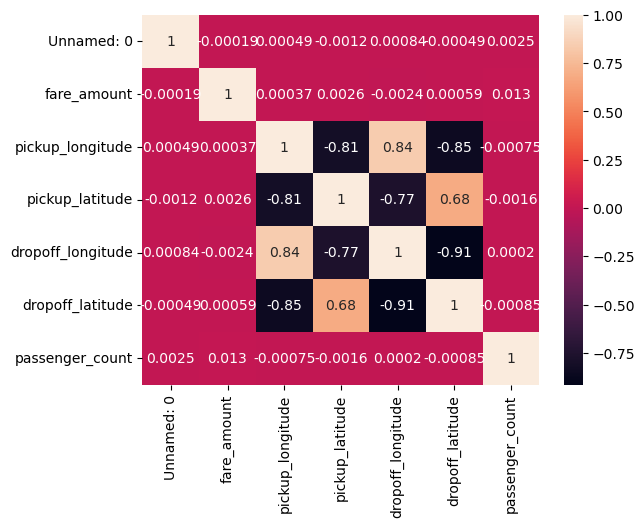

In [8]:
sns.heatmap(df.select_dtypes('number').corr(), annot=True)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

X = df[['pickup_longitude', 'pickup_latitude',
        'dropoff_longitude', 'dropoff_latitude',
        'passenger_count']]

y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
rf = RandomForestRegressor(n_estimators=10, random_state=42)

lr.fit(X_train, y_train)
rf.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [10]:
from sklearn.metrics import r2_score, mean_squared_error

for model in [lr, rf]:
    pred = model.predict(X_test)
    print(type(model).__name__)
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

LinearRegression
R2 Score: 8.297133767509735e-05
RMSE: 4.136624287486402
RandomForestRegressor
R2 Score: 0.6792090958743243
RMSE: 2.343015264782197
